# 07 – Train/Test Split and Preprocessing (S7)

**Course section:** Veri Ön İşleme — outliers, missing data, standardization, transformations, encoding. Before any data-driven preprocessing we fix the **holdout split**, so every later choice is learned from the training data only.

**Decision D13 (Tier 3, REVIEW #8 *approve with changes*, approved by the student):**
- One **shared holdout** for both tasks (price regression and Superhost classification), built on all 37,012 NYC listings.
- **Grouped by `host_id`**: no host appears in both train and test. Why: under a random 80/20 split 35.2% of test listings would have their host in train, 38.1% of listings belong to multi-listing hosts (largest NYC host: 255 listings), host-clustered SEs in S6 were 2.6× larger than HC3, and `host_is_superhost` is a host-level label (it would leak through the host's other listings).
- **Stratified on `room_type`** with `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)`; **fold 0 is the test set** (fixed before looking at any result). The real proportions are reported, not assumed to be exactly 80/20.
- Task subsets (`price > 0`, Superhost known) are filtered **after** the split, inside each side.
- Balance checks are **diagnostics, not pass/fail gates**: we do not re-draw the split to get nicer numbers.
- The assignment (`listing_id → split`) and a manifest are saved in `data/splits/`; `host_id` is used for grouping only, never as a feature.
- Evaluation scenario: **unseen hosts** (a conservative, realistic test for a pricing assistant used by new hosts). The test set stays locked until S14.

In [1]:
# --- Imports and settings ---
import sys, json, hashlib, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy import stats
from sklearn.model_selection import StratifiedGroupKFold

PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))
from configs.config import RANDOM_STATE, TARGET
from src.split_utils import SPLIT_PATH, attach_split, train_test

FIG_DIR = PROJECT_ROOT / "reports" / "figures"; TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
SPLIT_PATH.parent.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200)
def save(fig, name): fig.savefig(FIG_DIR / f"07_{name}.png", dpi=120, bbox_inches="tight")

df = pd.read_pickle(PROJECT_ROOT / "data" / "processed" / "ny_listings_enriched.pkl")
df["room_type"] = df["room_type"].astype(str); df["district"] = df["district"].astype(str)

# integrity checks before splitting
assert df["listing_id"].is_unique, "listing_id must be unique"
assert df["host_id"].notna().all(), "every listing needs a host_id for grouping"
print("listings:", len(df), "| hosts:", df["host_id"].nunique())
print(df["room_type"].value_counts().to_string())

listings: 37012 | hosts: 26765
room_type
Entire place    19397
Private room    16630
Shared room       686
Hotel room        299


## 1. Host-grouped, room-type-stratified split
`StratifiedGroupKFold` assigns whole hosts to folds while trying to keep the `room_type` mix similar in every fold. We look at all five folds to show they are similar in size, then use fold 0 as the test set, as decided before running.

In [2]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(sgkf.split(df, y=df["room_type"], groups=df["host_id"]))

fold_sizes = pd.DataFrame({"fold": range(5),
                           "test_rows": [len(te) for _, te in folds],
                           "test_hosts": [df["host_id"].iloc[te].nunique() for _, te in folds]})
fold_sizes["test_share_%"] = (fold_sizes["test_rows"] / len(df) * 100).round(2)
print(fold_sizes.to_string(index=False))

train_idx, test_idx = folds[0]                       # pre-registered choice: fold 0 = test
split = np.full(len(df), "train", dtype=object); split[test_idx] = "test"
df["split"] = split

train_hosts = set(df.loc[df["split"] == "train", "host_id"])
test_hosts = set(df.loc[df["split"] == "test", "host_id"])
overlap = train_hosts & test_hosts
assert not overlap, "a host appears in both train and test"
print(f"\ntrain: {(df.split == 'train').sum()} rows / {len(train_hosts)} hosts | "
      f"test: {(df.split == 'test').sum()} rows / {len(test_hosts)} hosts | host overlap: {len(overlap)}")
print("actual test share: {:.2%}".format((df.split == "test").mean()))

 fold  test_rows  test_hosts  test_share_%
    0       7403        5355          20.0
    1       7402        5352          20.0
    2       7402        5357          20.0
    3       7402        5349          20.0
    4       7403        5352          20.0

train: 29609 rows / 21410 hosts | test: 7403 rows / 5355 hosts | host overlap: 0
actual test share: 20.00%


## 2. Task subsets inside each side
Regression uses `price > 0`; classification uses listings with a known Superhost flag. Both are filtered after the split, so they inherit the same host-disjoint partition.

In [3]:
tasks = {"all listings": df,
         "regression (price > 0)": df[df[TARGET] > 0],
         "classification (superhost known)": df[df["host_is_superhost"].notna()]}
rows = []
for name, d in tasks.items():
    for s in ["train", "test"]:
        part = d[d["split"] == s]
        rows.append({"task": name, "split": s, "rows": len(part), "hosts": part["host_id"].nunique(),
                     "row_share_%": round(len(part) / len(d) * 100, 2)})
    tr, te = set(d.loc[d.split == "train", "host_id"]), set(d.loc[d.split == "test", "host_id"])
    assert not (tr & te), f"host overlap in task {name}"
task_counts = pd.DataFrame(rows)
print(task_counts.to_string(index=False))

                            task split  rows  hosts  row_share_%
                    all listings train 29609  21410         80.0
                    all listings  test  7403   5355         20.0
          regression (price > 0) train 29587  21392         80.0
          regression (price > 0)  test  7397   5350         20.0
classification (superhost known) train 29594  21397         80.0
classification (superhost known)  test  7400   5352         20.0


## 3. Balance diagnostics
Shares of `room_type` and borough, Superhost prevalence, the log-price distribution, the share of very expensive listings (> $1,000) and the weight of the largest hosts in each part. The KS statistic is reported as a descriptive distance between the two log-price distributions, not as a test to pass.

In [4]:
def share_table(col, d=df):
    t = pd.crosstab(d[col], d["split"], normalize="columns").mul(100)
    t["overall"] = d[col].value_counts(normalize=True).mul(100)
    t["diff_pp (test-train)"] = t["test"] - t["train"]
    return t[["overall", "train", "test", "diff_pp (test-train)"]].round(2)

print("room_type share (%)"); rt_tab = share_table("room_type"); print(rt_tab.to_string())
print("\nborough share (%)"); bo_tab = share_table("district"); print(bo_tab.to_string())

clf = tasks["classification (superhost known)"]
sh = clf.groupby("split")["host_is_superhost"].apply(lambda s: s.astype(bool).mean() * 100).round(2)
print("\nSuperhost prevalence (% of listings):", sh.to_dict(),
      "| overall:", round(clf["host_is_superhost"].astype(bool).mean() * 100, 2))

room_type share (%)
split         overall  train   test  diff_pp (test-train)
room_type                                                
Entire place    52.41  52.41  52.41                   0.0
Hotel room       0.81   0.81   0.81                   0.0
Private room    44.93  44.93  44.93                  -0.0
Shared room      1.85   1.85   1.85                  -0.0

borough share (%)
split          overall  train   test  diff_pp (test-train)
district                                                  
Bronx             2.68   2.67   2.70                  0.03
Brooklyn         39.11  38.74  40.58                  1.84
Manhattan        44.72  45.16  42.97                 -2.19
Queens           12.71  12.66  12.90                  0.24
Staten Island     0.78   0.76   0.85                  0.09

Superhost prevalence (% of listings): {'test': 17.07, 'train': 19.29} | overall: 18.84


In [5]:
reg = tasks["regression (price > 0)"].copy()
reg["log_price"] = np.log1p(reg[TARGET])
q = [0.05, 0.25, 0.5, 0.75, 0.95]
price_tab = reg.groupby("split")["log_price"].quantile(q).unstack()
price_tab.columns = [f"q{int(x * 100)}" for x in q]
price_tab["median_usd"] = reg.groupby("split")[TARGET].median()
price_tab["mean_log"] = reg.groupby("split")["log_price"].mean()
price_tab["share_>1000_%"] = reg.groupby("split")[TARGET].apply(lambda s: (s > 1000).mean() * 100)
print(price_tab.round(3).to_string())

ks = stats.ks_2samp(reg.loc[reg.split == "train", "log_price"], reg.loc[reg.split == "test", "log_price"])
print(f"\nKS distance between train and test log-price: D = {ks.statistic:.4f} (descriptive only)")

          q5    q25    q50    q75    q95  median_usd  mean_log  share_>1000_%
split                                                                        
test   3.526  4.111  4.605  5.112  5.861        99.0     4.642          0.514
train  3.584  4.111  4.605  5.017  5.855        99.0     4.629          0.669

KS distance between train and test log-price: D = 0.0307 (descriptive only)


In [6]:
# --- Weight of the largest hosts in each part ---
host_sizes = df.groupby(["split", "host_id"]).size().rename("n").reset_index()
big = []
for s in ["train", "test"]:
    hs = host_sizes[host_sizes.split == s].sort_values("n", ascending=False)
    total = hs["n"].sum()
    big.append({"split": s,
                "largest_host_listings": int(hs["n"].iloc[0]),
                "largest_host_share_%": round(hs["n"].iloc[0] / total * 100, 2),
                "top5_hosts_share_%": round(hs["n"].head(5).sum() / total * 100, 2),
                "single_listing_host_rows_%": round(hs.loc[hs.n == 1, "n"].sum() / total * 100, 2),
                "rows_from_hosts_>=10_%": round(hs.loc[hs.n >= 10, "n"].sum() / total * 100, 2)})
host_tab = pd.DataFrame(big)
print(host_tab.to_string(index=False))

top10 = df.groupby("host_id").agg(n=("listing_id", "size"), split=("split", "first")).nlargest(10, "n")
print("\nTen largest NYC hosts and where they landed:"); print(top10.to_string())

split  largest_host_listings  largest_host_share_%  top5_hosts_share_%  single_listing_host_rows_%  rows_from_hosts_>=10_%
train                    181                  0.61                2.45                       61.92                   10.90
 test                    255                  3.44                6.61                       61.96                   10.98

Ten largest NYC hosts and where they landed:
             n  split
host_id              
107434423  255   test
305240193  181  train
137358866  164  train
51501835   136  train
61391963   122  train
334163301  121  train
19303369   117  train
22541573    88  train
204704622   88   test
200239515   77   test


In [7]:
# --- How much does the single largest host (255 listings, all in test) move the test diagnostics? ---
big_id = top10.index[0]
b = df[df["host_id"] == big_id]
print(f"largest host {big_id}: {len(b)} listings | split: {list(b['split'].unique())} | boroughs: {b['district'].value_counts().to_dict()} | "
      f"room types: {b['room_type'].value_counts().to_dict()} | superhost: {b['host_is_superhost'].astype(str).value_counts().to_dict()} | "
      f"median price: {b[TARGET].median():.0f}")
te = df[df["split"] == "test"]; te_x = te[te["host_id"] != big_id]
def sh_pct(d):
    k = d[d["host_is_superhost"].notna()]; return round(k["host_is_superhost"].astype(bool).mean() * 100, 2)
print(pd.DataFrame({"train": [sh_pct(df[df.split == "train"]), round((df[df.split == "train"]["district"] == "Manhattan").mean() * 100, 2)],
                    "test": [sh_pct(te), round((te["district"] == "Manhattan").mean() * 100, 2)],
                    "test without largest host": [sh_pct(te_x), round((te_x["district"] == "Manhattan").mean() * 100, 2)]},
                   index=["superhost %", "Manhattan %"]).to_string())

largest host 107434423: 255 listings | split: ['test'] | boroughs: {'Manhattan': 255} | room types: {'Entire place': 255} | superhost: {'False': 255} | median price: 250
             train   test  test without largest host
superhost %  19.29  17.07                      17.68
Manhattan %  45.16  42.97                      40.93


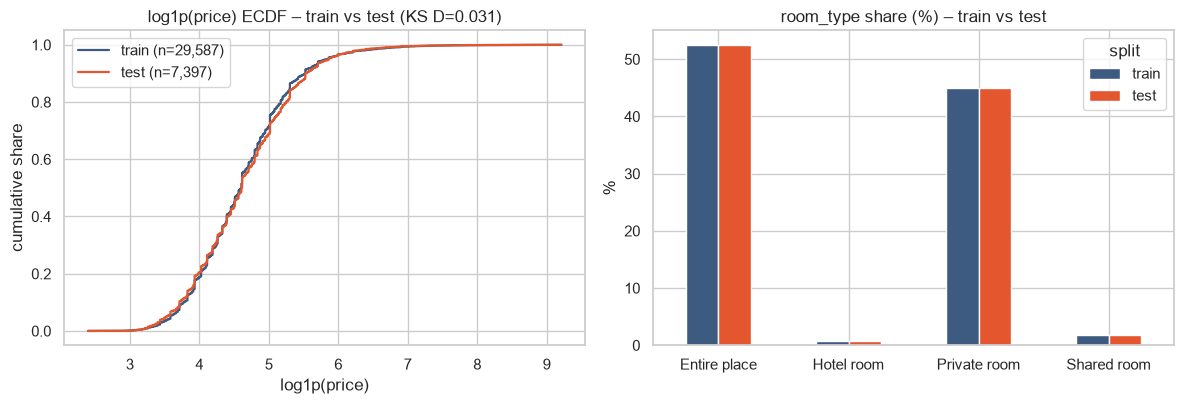

In [8]:
# --- Figure: train vs test log-price ECDF and room-type mix ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for s, c in [("train", "#3D5A80"), ("test", "#E4572E")]:
    x = np.sort(reg.loc[reg.split == s, "log_price"]); y = np.arange(1, len(x) + 1) / len(x)
    axes[0].plot(x, y, label=f"{s} (n={len(x):,})", color=c, lw=1.6)
axes[0].set(title=f"log1p(price) ECDF – train vs test (KS D={ks.statistic:.3f})", xlabel="log1p(price)", ylabel="cumulative share")
axes[0].legend()
rt_tab[["train", "test"]].plot.bar(ax=axes[1], color=["#3D5A80", "#E4572E"], rot=0)
axes[1].set(title="room_type share (%) – train vs test", xlabel="", ylabel="%")
plt.tight_layout(); save(fig, "01_split_balance"); plt.show()

## 4. Save the assignment and the manifest
Only ids and labels are saved (no data). Later notebooks call `src.split_utils.train_test(df)` to get exactly the same partition.

In [9]:
split_df = df[["listing_id", "split"]].sort_values("listing_id")
split_df.to_csv(SPLIT_PATH, index=False)

raw_file = PROJECT_ROOT / "data" / "raw" / "Listings.csv"
sha = hashlib.sha256()
with open(raw_file, "rb") as fh:
    for chunk in iter(lambda: fh.read(1 << 20), b""):
        sha.update(chunk)

manifest = {
    "decision": "D13", "review": "REVIEW #8 (approve with changes)",
    "method": "StratifiedGroupKFold(n_splits=5, shuffle=True)", "random_state": RANDOM_STATE,
    "test_fold": 0, "group": "host_id", "stratify": "room_type",
    "source_file": "data/raw/Listings.csv (city == New York)", "source_sha256": sha.hexdigest(),
    "n_listings": int(len(df)), "n_train": int((df.split == "train").sum()), "n_test": int((df.split == "test").sum()),
    "n_hosts_train": len(train_hosts), "n_hosts_test": len(test_hosts), "host_overlap": len(overlap),
    "task_counts": task_counts.to_dict(orient="records"),
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "sklearn": sklearn.__version__},
}
(SPLIT_PATH.parent / "split_manifest.json").write_text(json.dumps(manifest, indent=2))

balance = pd.concat({"room_type": rt_tab, "borough": bo_tab})
balance.to_csv(TABLE_DIR / "07_split_balance.csv")
host_tab.to_csv(TABLE_DIR / "07_split_hosts.csv", index=False)

# re-load check: the helper must reproduce the same partition
train_df, test_df = train_test(df.drop(columns="split"))
assert len(train_df) == manifest["n_train"] and len(test_df) == manifest["n_test"]
assert set(train_df["host_id"]).isdisjoint(test_df["host_id"])
print("saved:", SPLIT_PATH.relative_to(PROJECT_ROOT), "+ split_manifest.json | reload check OK")
print(json.dumps({k: manifest[k] for k in ["n_train", "n_test", "n_hosts_train", "n_hosts_test", "host_overlap"]}))

saved: data/splits/train_test_split.csv + split_manifest.json | reload check OK
{"n_train": 29609, "n_test": 7403, "n_hosts_train": 21410, "n_hosts_test": 5355, "host_overlap": 0}


In [10]:
# --- src/ tests (now 13, incl. the split helpers) ---
from tests.test_src import run_all
print(run_all().to_string(index=False))

                                                    test result error
                                    test_find_tf_columns   PASS      
                              test_to_bool_keeps_missing   PASS      
                              test_parse_amenities_valid   PASS      
                          test_parse_amenities_bad_input   PASS      
                                     test_missing_report   PASS      
                        test_checker_finds_duplicate_ids   PASS      
                      test_checker_range_ignores_missing   PASS      
                      test_checker_unknown_column_raises   PASS      
                      test_checker_rejects_non_dataframe   PASS      
                           test_assert_clean_strict_mode   PASS      
                           test_load_missing_file_raises   PASS      
                   test_train_test_uses_saved_assignment   PASS      
            test_attach_split_rejects_unassigned_listing   PASS      
                    

## Split – interim evaluation
**What we did:** host-grouped, room-type-stratified 80/20 holdout (`StratifiedGroupKFold`, fold 0, seed 42) on all 37,012 listings; saved `data/splits/train_test_split.csv` + `split_manifest.json`; helper `src.split_utils.train_test` reproduces it (13/13 src tests pass).

**Findings:**
- Sizes: train 29,609 listings / 21,410 hosts, test 7,403 / 5,355 (exactly 20.00%); **0 hosts in both**. Regression subset 29,587 / 7,397, classification subset 29,594 / 7,400 – both keep the 80/20 host-disjoint partition.
- `room_type` mix is identical (stratification worked). Log-price distributions are very close (same median $99, q25/q50 equal, KS D = 0.031); test has a slightly heavier q75 (5.11 vs 5.02) and fewer > $1,000 listings (0.51% vs 0.67%).
- Borough: test has more Brooklyn (+1.8 pp) and less Manhattan (−2.2 pp). Superhost prevalence is lower in test (17.1% vs 19.3%).
- The largest NYC host (255 entire places in Manhattan, not a Superhost, median $250) is fully in test (3.4% of test rows). It explains part of the Superhost gap (test without it: 17.7%) but not the Manhattan gap. This is the expected consequence of an unseen-host test, so it is **not** moved; its contribution to test metrics will be reported in S14.

**Decision kept:** no re-drawing of the split (REVIEW #8). Differences are small and documented; for classification, PR-AUC must be read against the test prevalence (17.1%), not the training one.

**Next step:** preprocessing audit on the **training set only** – outliers (price tail, minimum/maximum nights placeholders), missing-data groups, encoding of high-cardinality `neighbourhood`, scaling – then a Tier 2 consult before applying anything.

# Part B – Preprocessing audit on the training set only (D14)
**Plan reviewed by ChatGPT (REVIEW #9, approved with changes).** This part is **read-only**: it looks at the training data and fits nothing that will be used for scoring. Every learned step (capping thresholds, imputers, encoders, scalers) will later sit inside an sklearn `Pipeline` / `ColumnTransformer` that is fitted inside each CV fold.

Rules applied:
- The test part of the split is never loaded below.
- IQR and LOF flags are **diagnostics**, not reasons to delete rows. Price outliers are not dropped by default (log target + capping sensitivity later); any permanent row exclusion would be a Tier 3 decision.
- We separate **invalid** values (impossible, placeholders) from **legitimate extremes** (real luxury listings).
- Order: target → numeric distributions and validity → missing data → categorical variables and encoding → scaling needs. The audit ends with CONSULT #10, listing a concrete treatment for each variable.

In [11]:
# --- Training data only ---
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from src.data_utils import missing_report, parse_amenities

train, _unused_test = train_test(df.drop(columns="split"))
del _unused_test                                    # the test part is not used anywhere in this audit
SNAPSHOT = pd.Timestamp("2021-02-05")               # last NYC review date (S4)

tr = train.copy()
tr["amenity_list"] = tr["amenities"].apply(parse_amenities)
tr["n_amenities"] = tr["amenity_list"].apply(len)
tr["host_tenure_days"] = (SNAPSHOT - pd.to_datetime(tr["host_since"])).dt.days
tr["host_ny_listings"] = tr.groupby("host_id")["listing_id"].transform("size")   # all of a host's NYC listings are on one side
reg_tr = tr[tr[TARGET] > 0].copy()
reg_tr["log_price"] = np.log1p(reg_tr[TARGET])
print("train listings:", len(tr), "| regression rows (price > 0):", len(reg_tr), "| price == 0:", int((tr[TARGET] == 0).sum()))

train listings: 29609 | regression rows (price > 0): 29587 | price == 0: 22


## 5. Target: the price tail and suspicious values

In [12]:
p_ = reg_tr[TARGET]
print("price quantiles (USD):")
print(p_.quantile([0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]).round(1).to_string())

tail = pd.Series({
    "< $10": (p_ < 10).sum(), "< $20": (p_ < 20).sum(),
    "> $1,000": (p_ > 1000).sum(), "> $2,000": (p_ > 2000).sum(), "> $5,000": (p_ > 5000).sum(),
    ">= $9,999": (p_ >= 9999).sum(),
    "private/shared room and > $1,000": (reg_tr["room_type"].isin(["Private room", "Shared room"]) & (p_ > 1000)).sum(),
    "price per guest > $500": ((p_ / reg_tr["accommodates"].clip(lower=1)) > 500).sum(),
    "entire place and < $20": ((reg_tr["room_type"] == "Entire place") & (p_ < 20)).sum(),
}).astype(int)
print("\nsuspicious / extreme counts:"); print(tail.to_string())

show = ["listing_id", TARGET, "room_type", "property_type", "district", "accommodates", "bedrooms", "minimum_nights", "n_reviews"]
print("\nhighest prices:"); print(reg_tr.nlargest(12, TARGET)[show].to_string(index=False))
print("\nlowest prices:"); print(reg_tr.nsmallest(8, TARGET)[show].to_string(index=False))
print("\nshare > $1,000 by room_type (%):")
print(reg_tr.groupby("room_type")[TARGET].apply(lambda s: round((s > 1000).mean() * 100, 2)).to_string())
print("\nreviews for listings > $1,000: share with 0 reviews = {:.1%} (all train: {:.1%})".format(
    (reg_tr.loc[p_ > 1000, "n_reviews"] == 0).mean(), (reg_tr["n_reviews"] == 0).mean()))

price quantiles (USD):
0.001      18.0
0.010      25.0
0.050      35.0
0.250      60.0
0.500      99.0
0.750     150.0
0.950     348.0
0.990     870.7
0.999    3082.8

suspicious / extreme counts:
< $10                                 0
< $20                                48
> $1,000                            198
> $2,000                             54
> $5,000                             20
>= $9,999                            10
private/shared room and > $1,000     53
price per guest > $500              103
entire place and < $20                2

highest prices:
 listing_id  price    room_type             property_type  district  accommodates  bedrooms  minimum_nights  n_reviews
   13925864  10000 Entire place          Entire apartment    Queens             4       2.0              30         28
   39100961  10000 Private room    Room in boutique hotel Manhattan             2       1.0              30          0
   22985168  10000 Entire place        Entire condominium    Queens  

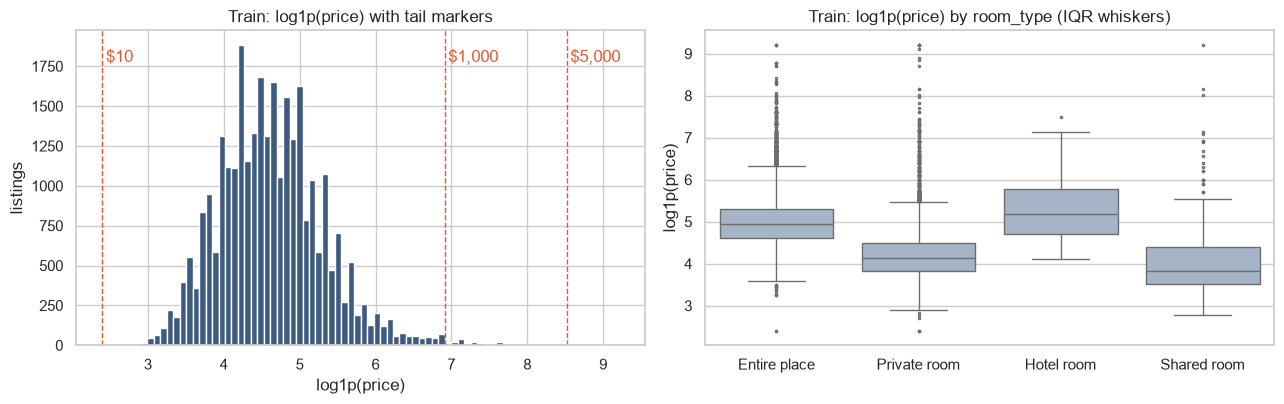

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(reg_tr["log_price"], bins=80, color="#3D5A80")
for v, lab in [(10, "$10"), (1000, "$1,000"), (5000, "$5,000")]:
    axes[0].axvline(np.log1p(v), color="#E4572E", ls="--", lw=1); axes[0].text(np.log1p(v) + 0.05, axes[0].get_ylim()[1] * 0.9, lab, color="#E4572E")
axes[0].set(title="Train: log1p(price) with tail markers", xlabel="log1p(price)", ylabel="listings")
sns.boxplot(data=reg_tr, x="room_type", y="log_price", ax=axes[1], color="#9FB4CC", fliersize=1.5)
axes[1].set(title="Train: log1p(price) by room_type (IQR whiskers)", xlabel="", ylabel="log1p(price)")
plt.tight_layout(); save(fig, "02_target_tail"); plt.show()

## 6. Numeric variables: validity checks, IQR diagnostics, LOF
**Domain validity first** – impossible values and system placeholders are a different problem from real extremes.

In [14]:
in_box = tr["latitude"].between(40.49, 40.92) & tr["longitude"].between(-74.27, -73.68)
checks = pd.Series({
    "accommodates == 0": (tr["accommodates"] == 0).sum(),
    "bedrooms == 0": (tr["bedrooms"] == 0).sum(),
    "bedrooms missing": tr["bedrooms"].isna().sum(),
    "bedrooms > accommodates": (tr["bedrooms"] > tr["accommodates"]).sum(),
    "minimum_nights > maximum_nights": (tr["minimum_nights"] > tr["maximum_nights"]).sum(),
    "minimum_nights >= 30 (NYC short-stay rule)": (tr["minimum_nights"] >= 30).sum(),
    "minimum_nights > 365": (tr["minimum_nights"] > 365).sum(),
    "maximum_nights == 1125 (Airbnb default)": (tr["maximum_nights"] == 1125).sum(),
    "maximum_nights > 1125": (tr["maximum_nights"] > 1125).sum(),
    "maximum_nights >= 1,000,000": (tr["maximum_nights"] >= 1_000_000).sum(),
    "host_total_listings_count == 0": (tr["host_total_listings_count"] == 0).sum(),
    "host_total_listings_count < NYC listings of host": (tr["host_total_listings_count"] < tr["host_ny_listings"]).sum(),
    "coordinates outside NYC box": (~in_box).sum(),
    "host_since after snapshot": (tr["host_tenure_days"] < 0).sum(),
    "n_amenities == 0": (tr["n_amenities"] == 0).sum(),
}).astype(int)
validity = checks.to_frame("n_train"); validity["pct"] = (validity["n_train"] / len(tr) * 100).round(2)
print(validity.to_string())
print("\nmost common minimum_nights:", tr["minimum_nights"].value_counts().head(8).to_dict())
print("most common maximum_nights:", tr["maximum_nights"].value_counts().head(8).to_dict())
print("maximum_nights max:", int(tr["maximum_nights"].max()))

                                                  n_train    pct
accommodates == 0                                      10   0.03
bedrooms == 0                                           0   0.00
bedrooms missing                                     2933   9.91
bedrooms > accommodates                               158   0.53
minimum_nights > maximum_nights                         1   0.00
minimum_nights >= 30 (NYC short-stay rule)          19778  66.80
minimum_nights > 365                                   16   0.05
maximum_nights == 1125 (Airbnb default)             16450  55.56
maximum_nights > 1125                                  12   0.04
maximum_nights >= 1,000,000                             2   0.01
host_total_listings_count == 0                       3692  12.47
host_total_listings_count < NYC listings of host     6100  20.60
coordinates outside NYC box                             0   0.00
host_since after snapshot                               0   0.00
n_amenities == 0         

In [15]:
# --- IQR diagnostics (Tukey fences, k = 1.5) and skewness before / after log1p ---
num_cols = ["accommodates", "bedrooms", "minimum_nights", "maximum_nights", "host_total_listings_count",
            "host_response_rate", "host_acceptance_rate", "n_amenities", "host_tenure_days", "latitude", "longitude"]
rows = []
for c in num_cols + ["log_price"]:
    s = (reg_tr if c == "log_price" else tr)[c].dropna().astype(float)
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"variable": c, "n": len(s), "q1": q1, "median": s.median(), "q3": q3, "lower_fence": lo, "upper_fence": hi,
                 "n_below": int((s < lo).sum()), "n_above": int((s > hi).sum()),
                 "pct_flagged": round(((s < lo) | (s > hi)).mean() * 100, 2),
                 "max": s.max(), "skew": round(s.skew(), 2),
                 "skew_log1p": round(np.log1p(s).skew(), 2) if s.min() >= 0 and c not in ("log_price", "latitude", "longitude") else np.nan})
iqr_tab = pd.DataFrame(rows).set_index("variable")
print(iqr_tab.round(3).to_string())
print("\nNote: IQR fences on a 0-1 rate or a count with a small IQR flag many valid values; they are diagnostics only.")

                               n        q1    median        q3  lower_fence  upper_fence  n_below  n_above  pct_flagged           max    skew  skew_log1p
variable                                                                                                                                                 
accommodates               29609     2.000     2.000     4.000       -1.000        7.000        0      778         2.63  1.600000e+01    2.45        0.71
bedrooms                   26676     1.000     1.000     1.000        1.000        1.000        0     5847        21.92  2.100000e+01    4.14        2.14
minimum_nights             29609     4.000    30.000    30.000      -35.000       69.000        0      389         1.31  1.250000e+03   15.19       -0.80
maximum_nights             29609    90.000  1125.000  1125.000    -1462.500     2677.500        0        7         0.02  2.147484e+09  172.05       -0.83
host_total_listings_count  29594     1.000     1.000     2.000       -0.500 

**LOF (Local Outlier Factor)** – a density-based, multivariate view (course demo). Features: location, capacity, log minimum nights and log price, standardized. LOF compares each point's local density with its 20 neighbours; scores clearly above 1 mean "isolated in its neighbourhood". Used only to look at the flagged listings, not to remove them.

LOF score quantiles: {0.5: 1.04, 0.9: 1.25, 0.95: 1.39, 0.99: 1.96, 0.999: 2.97}
sklearn default flag (score > 1.5): 989 rows (3.34%) | top-1% threshold: 1.96

medians, top-1% LOF vs rest:
             price  accommodates  minimum_nights      n  share_staten_bronx_%
top1pct_lof                                                                  
False         99.0           2.0            30.0  29291                   3.5
True          93.5           2.0            30.0    296                   2.0

highest LOF scores:
 listing_id  price    room_type             property_type  district  accommodates  bedrooms  minimum_nights  n_reviews  lof_score
   23485307     79 Private room      Private room in loft Manhattan             2       NaN               2        119      10.81
    8012976     69 Private room Private room in apartment Manhattan             2       1.0               1        152       6.93
    6633613     85 Private room Private room in apartment Manhattan             1       

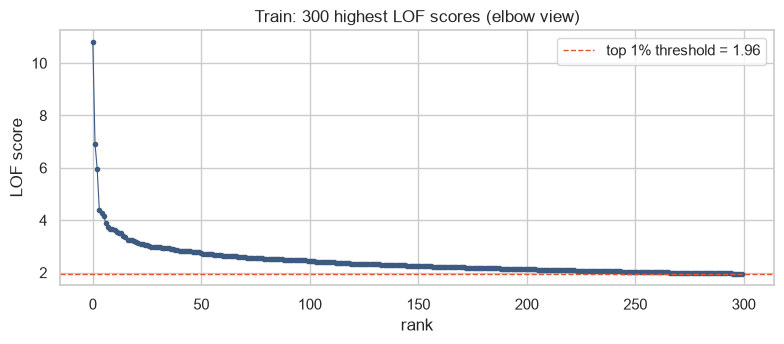

In [16]:
lof_cols = ["latitude", "longitude", "accommodates", "log_min_nights", "log_price"]
X_lof = reg_tr.assign(log_min_nights=np.log1p(reg_tr["minimum_nights"]))[lof_cols]
Xs = StandardScaler().fit_transform(X_lof)
lof = LocalOutlierFactor(n_neighbors=20)
lof_label = lof.fit_predict(Xs)
reg_tr["lof_score"] = -lof.negative_outlier_factor_

thr = reg_tr["lof_score"].quantile(0.99)
print("LOF score quantiles:", reg_tr["lof_score"].quantile([0.5, 0.9, 0.95, 0.99, 0.999]).round(2).to_dict())
print(f"sklearn default flag (score > 1.5): {(lof_label == -1).sum()} rows ({(lof_label == -1).mean():.2%}) | top-1% threshold: {thr:.2f}")
flag = reg_tr["lof_score"] > thr
comp = reg_tr.groupby(flag.rename("top1pct_lof"))[[TARGET, "accommodates", "minimum_nights"]].median()
comp["n"] = flag.value_counts(); comp["share_staten_bronx_%"] = reg_tr.groupby(flag)["district"].apply(lambda s: round(s.isin(["Staten Island", "Bronx"]).mean() * 100, 1))
print("\nmedians, top-1% LOF vs rest:"); print(comp.to_string())
print("\nhighest LOF scores:"); print(reg_tr.nlargest(6, "lof_score")[show + ["lof_score"]].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(np.sort(reg_tr["lof_score"].values)[::-1][:300], marker=".", lw=0.8, color="#3D5A80")
ax.axhline(thr, color="#E4572E", ls="--", lw=1, label=f"top 1% threshold = {thr:.2f}")
ax.set(title="Train: 300 highest LOF scores (elbow view)", xlabel="rank", ylabel="LOF score"); ax.legend()
plt.tight_layout(); save(fig, "03_lof_scores"); plt.show()

## 7. Missing data on the training set
S5 found three groups (host profile, host activity, review scores) plus `bedrooms`. Here we re-check them on train only and ask two questions for each: is the missingness **structural** (the value cannot exist) or **ordinary**, and is it **informative** (related to price or Superhost status)?

                             n_missing  pct_missing
host_response_time               14781        49.92
host_response_rate               14781        49.92
host_acceptance_rate             11684        39.46
review_scores_value               8097        27.35
review_scores_location            8097        27.35
review_scores_checkin             8096        27.34
review_scores_accuracy            8087        27.31
review_scores_communication       8086        27.31
review_scores_cleanliness         8078        27.28
review_scores_rating              8067        27.25
last_review                       7491        25.30
first_review                      7491        25.30
bedrooms                          2933         9.91
host_location                       99         0.33
host_tenure_years                   15         0.05
host_tenure_days                    15         0.05
host_since                          15         0.05
host_identity_verified              15         0.05
host_has_pro

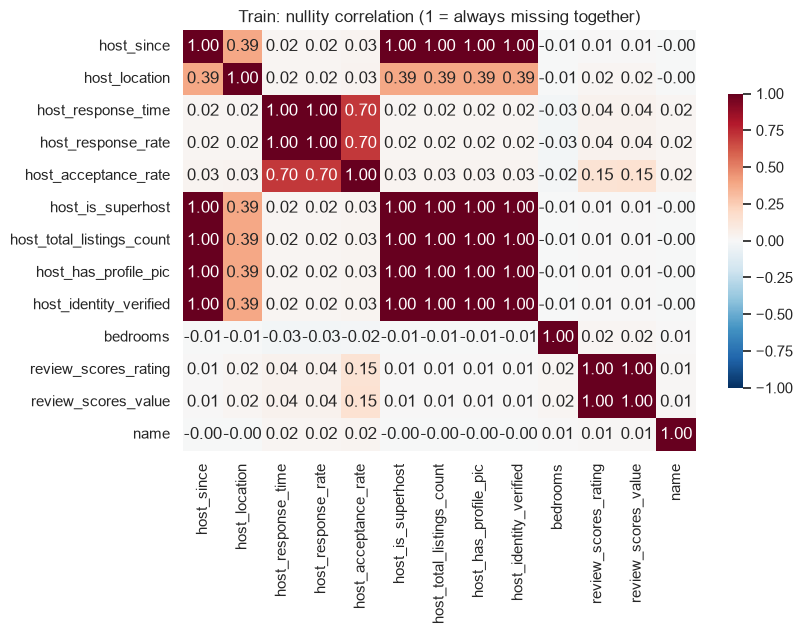


most common missingness patterns (response_rate, acceptance_rate, bedrooms, review_rating; 1 = missing):
0000    9582
1100    6535
1101    3366
1000    3028
0001    2968
0010    1114
1110     664
1001     502


In [17]:
model_cols = ["host_since", "host_location", "host_response_time", "host_response_rate", "host_acceptance_rate",
              "host_is_superhost", "host_total_listings_count", "host_has_profile_pic", "host_identity_verified",
              "bedrooms", "review_scores_rating", "review_scores_value", "name"]
miss_tab = missing_report(tr[[c for c in tr.columns if c not in ("amenity_list",)]])
print(miss_tab.to_string())

ind = tr[model_cols].isna()
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(ind.loc[:, ind.any()].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Train: nullity correlation (1 = always missing together)")
plt.tight_layout(); save(fig, "04_nullity_correlation"); plt.show()

pattern = ind[["host_response_rate", "host_acceptance_rate", "bedrooms", "review_scores_rating"]].astype(int).astype(str).agg("".join, axis=1)
print("\nmost common missingness patterns (response_rate, acceptance_rate, bedrooms, review_rating; 1 = missing):")
print(pattern.value_counts().head(8).to_string())

In [18]:
# --- Structural or ordinary? ---
print("review_scores_rating missing vs listing has 0 reviews:")
print(pd.crosstab(tr["review_scores_rating"].isna(), tr["n_reviews"] == 0, margins=True).to_string())
print("\nhost_response_rate missing vs host_response_time missing:")
print(pd.crosstab(tr["host_response_rate"].isna(), tr["host_response_time"].isna()).to_string())
print("\nbedrooms missing rate by room_type (%):", tr.groupby("room_type")["bedrooms"].apply(lambda s: round(s.isna().mean() * 100, 1)).to_dict())
print("bedrooms missing rate by accommodates (1, 2, 3-4, 5+) (%):",
      tr.groupby(pd.cut(tr["accommodates"], [0, 1, 2, 4, 100], labels=["1", "2", "3-4", "5+"]), observed=True)["bedrooms"]
        .apply(lambda s: round(s.isna().mean() * 100, 1)).to_dict())
print("property types with most missing bedrooms:",
      tr.loc[tr["bedrooms"].isna(), "property_type"].value_counts().head(5).to_dict())

# --- Informative? median log price and superhost share with / without each missing value ---
rows = []
for c in ["host_response_rate", "host_acceptance_rate", "bedrooms", "review_scores_rating", "host_since"]:
    m = reg_tr[c].isna()
    sh_ = tr.groupby(tr[c].isna())["host_is_superhost"].apply(lambda s: s.dropna().astype(bool).mean() * 100)
    rows.append({"variable": c, "pct_missing": round(m.mean() * 100, 2),
                 "median_price_missing": reg_tr.loc[m, TARGET].median(), "median_price_present": reg_tr.loc[~m, TARGET].median(),
                 "superhost_%_missing": round(sh_.get(True, np.nan), 1), "superhost_%_present": round(sh_.get(False, np.nan), 1)})
informative = pd.DataFrame(rows).set_index("variable")
print("\nIs missingness related to the targets?"); print(informative.to_string())

review_scores_rating missing vs listing has 0 reviews:
n_reviews             False  True    All
review_scores_rating                    
False                 21542     0  21542
True                    576  7491   8067
All                   22118  7491  29609

host_response_rate missing vs host_response_time missing:
host_response_time  False  True 
host_response_rate              
False               14828      0
True                    0  14781

bedrooms missing rate by room_type (%): {'Entire place': 16.2, 'Hotel room': 15.9, 'Private room': 2.9, 'Shared room': 0.0}
bedrooms missing rate by accommodates (1, 2, 3-4, 5+) (%): {'1': 5.3, '2': 13.0, '3-4': 11.0, '5+': 2.4}
property types with most missing bedrooms: {'Entire apartment': 2132, 'Private room in apartment': 199, 'Entire condominium': 99, 'Entire loft': 91, 'Entire serviced apartment': 64}

Is missingness related to the targets?
                      pct_missing  median_price_missing  median_price_present  superhost_%_missin

## 8. Categorical variables, amenities and encoding

In [19]:
cat_cols = ["neighbourhood", "district", "property_type", "room_type", "host_response_time", "host_location"]
rows = []
for c in cat_cols:
    vc = tr[c].value_counts(dropna=True)
    cum = vc.cumsum() / vc.sum()
    rows.append({"variable": c, "levels": len(vc), "top_level": vc.index[0], "top_share_%": round(vc.iloc[0] / vc.sum() * 100, 1),
                 "levels_<10_rows": int((vc < 10).sum()), "levels_<30_rows": int((vc < 30).sum()),
                 "rows_in_levels_<30_%": round(vc[vc < 30].sum() / vc.sum() * 100, 2),
                 "levels_for_95%_rows": int((cum < 0.95).sum() + 1)})
card = pd.DataFrame(rows).set_index("variable"); print(card.to_string())

print("\nhost_location mentions New York: {:.1%}".format(tr["host_location"].str.contains("New York", na=False).mean()))
print("host_response_time levels:", tr["host_response_time"].value_counts().to_dict())

# one-hot width for neighbourhood with different min_frequency settings (rare levels -> one 'infrequent' column)
for mf in [1, 10, 30, 50, 100]:
    enc = OneHotEncoder(min_frequency=mf, handle_unknown="infrequent_if_exist").fit(tr[["neighbourhood"]])
    print(f"neighbourhood one-hot columns with min_frequency={mf}: {len(enc.get_feature_names_out())}")

                    levels                          top_level  top_share_%  levels_<10_rows  levels_<30_rows  rows_in_levels_<30_%  levels_for_95%_rows
variable                                                                                                                                               
neighbourhood          220                       Williamsburg          7.4               64              119                  3.95                   93
district                 5                          Manhattan         45.2                0                0                  0.00                    3
property_type           75                   Entire apartment         41.7               41               53                  1.07                   12
room_type                4                       Entire place         52.4                0                0                  0.00                    2
host_response_time       4                     within an hour         53.7              

In [20]:
# --- Amenities: from a JSON-like string to indicator candidates ---
exploded = tr[["listing_id", "amenity_list"]].explode("amenity_list").dropna()
am_share = exploded.groupby("amenity_list")["listing_id"].nunique().div(len(tr)).sort_values(ascending=False)
print("distinct amenities:", len(am_share), "| median per listing:", tr["n_amenities"].median())
print("amenities in 5-95% of listings (useful indicator candidates):", int(am_share.between(0.05, 0.95).sum()))
print("\nmost common:"); print((am_share.head(12) * 100).round(1).to_string())
key = ["Air conditioning", "Washer", "Dryer", "Dishwasher", "Elevator", "Free parking on premises", "Gym", "Doorman",
       "Patio or balcony", "Dedicated workspace", "TV", "Pool"]
print("\nselected amenities (% of train listings):", {k: round(am_share.get(k, 0) * 100, 1) for k in key})

distinct amenities: 663 | median per listing: 19.0
amenities in 5-95% of listings (useful indicator candidates): 44

most common:
amenity_list
Wifi                       97.0
Long term stays allowed    94.1
Heating                    93.8
Essentials                 90.9
Kitchen                    90.8
Smoke alarm                87.7
Air conditioning           85.4
Hangers                    75.8
Carbon monoxide alarm      72.6
TV                         69.9
Dedicated workspace        64.9
Hair dryer                 64.2

selected amenities (% of train listings): {'Air conditioning': 85.4, 'Washer': 41.7, 'Dryer': 41.0, 'Dishwasher': 17.7, 'Elevator': 23.4, 'Free parking on premises': 7.8, 'Gym': 10.3, 'Doorman': 0, 'Patio or balcony': 9.3, 'Dedicated workspace': 64.9, 'TV': 69.9, 'Pool': 1.7}


**Dummy variable trap.** With an intercept, keeping all *k* dummy columns of one categorical variable makes the design matrix rank-deficient: the dummies always sum to 1, which equals the intercept column. For linear models (OLS) we drop one reference level; regularized and tree models can keep all *k* columns.

In [21]:
D = pd.get_dummies(tr["room_type"], dtype=float)
X_all = np.column_stack([np.ones(len(D)), D.values])                 # intercept + all 4 dummies
X_ref = np.column_stack([np.ones(len(D)), D.drop(columns="Entire place").values])   # reference = Entire place
print("columns:", list(D.columns))
print(f"intercept + all {D.shape[1]} dummies: {X_all.shape[1]} columns, rank {np.linalg.matrix_rank(X_all)}  -> perfectly collinear")
print(f"intercept + {D.shape[1] - 1} dummies (drop 'Entire place'): {X_ref.shape[1]} columns, rank {np.linalg.matrix_rank(X_ref)} -> full rank")
print("pandas: get_dummies(drop_first=True) | sklearn: OneHotEncoder(drop='first') or drop=['Entire place']")

columns: ['Entire place', 'Hotel room', 'Private room', 'Shared room']
intercept + all 4 dummies: 5 columns, rank 4  -> perfectly collinear
intercept + 3 dummies (drop 'Entire place'): 4 columns, rank 4 -> full rank
pandas: get_dummies(drop_first=True) | sklearn: OneHotEncoder(drop='first') or drop=['Entire place']


## 9. Scaling needs
Distance- and gradient-based models (KNN, SVR/SVC, ANN, Ridge/Lasso/ElasticNet, PCA, K-Means) need features on comparable scales; tree ensembles (CART, RF, GBM, XGBoost, LightGBM, CatBoost) do not. The ranges below show why.

In [22]:
scale_cols = ["accommodates", "bedrooms", "minimum_nights", "maximum_nights", "host_total_listings_count",
              "host_acceptance_rate", "n_amenities", "host_tenure_days", "latitude"]
scale_tab = tr[scale_cols].astype(float).agg(["min", "median", "max", "std"]).T
scale_tab["max/std"] = (scale_tab["max"] / scale_tab["std"]).round(1)
print(scale_tab.round(3).to_string())
needs = pd.DataFrame({
    "model family": ["Linear / PCR / PLS", "Ridge / Lasso / ElasticNet", "KNN, SVR/SVC, ANN", "CART, RF, GBM, XGBoost, LightGBM, CatBoost", "PCA, K-Means, hierarchical"],
    "scaling": ["optional (needed for PCR/PLS)", "required (penalty depends on scale)", "required", "not needed", "required"],
    "one-hot": ["drop reference level", "all levels ok", "all levels ok", "all levels ok (CatBoost: native categories)", "use with care"],
    "skewed counts": ["log1p helps", "log1p helps", "log1p helps", "no effect on splits", "log1p helps"]})
print(); print(needs.to_string(index=False))

# save audit tables
validity.to_csv(TABLE_DIR / "07_audit_validity.csv"); iqr_tab.to_csv(TABLE_DIR / "07_audit_iqr.csv")
miss_tab.to_csv(TABLE_DIR / "07_audit_missing.csv"); informative.to_csv(TABLE_DIR / "07_audit_missing_informative.csv")
card.to_csv(TABLE_DIR / "07_audit_categorical.csv")
print("\naudit tables saved to reports/tables/07_audit_*.csv")

                              min    median           max           std  max/std
accommodates                0.000     2.000  1.600000e+01  1.844000e+00      8.7
bedrooms                    1.000     1.000  2.100000e+01  7.300000e-01     28.8
minimum_nights              1.000    30.000  1.250000e+03  2.732500e+01     45.7
maximum_nights              1.000  1125.000  2.147484e+09  1.248063e+07    172.1
host_total_listings_count   0.000     1.000  2.739000e+03  1.256140e+02     21.8
host_acceptance_rate        0.000     0.930  1.000000e+00  2.810000e-01      3.6
n_amenities                 1.000    19.000  7.800000e+01  9.144000e+00      8.5
host_tenure_days            3.000  2016.000  4.550000e+03  9.667350e+02      4.7
latitude                   40.509    40.726  4.091200e+01  5.500000e-02    747.2

                              model family                             scaling                                     one-hot       skewed counts
                        Linear / PCR / PLS    

## Audit – evaluation (train only, 29,609 listings)
**Target (price > 0, 29,587 rows):** median $99, 99th percentile $871, 99.9th $3,083. 198 listings > $1,000 (0.67%), 20 > $5,000. The top of the tail contains **round placeholder-like prices** (11 listings at $9,990–10,000, mostly Manhattan hotel/private rooms, often with 0 reviews; 56% of > $1,000 listings have no reviews vs 25% overall) and 53 private/shared rooms above $1,000. The low end looks plausible (min $10, 48 below $20). The log scale handles most of the skew (log-price skew 0.79).

**Numeric validity:** 10 listings with `accommodates = 0` (invalid). `maximum_nights` is mostly the Airbnb default 1125 (55.6%) with sentinels up to 2,147,483,647 (int32 max). `minimum_nights` is dominated by 30 (NYC rule; 66.8% ≥ 30), 16 listings > 365. `host_total_listings_count` is unreliable: 0 for 12.5% of listings and smaller than the host's own NYC listing count for 20.6%, so it is a poor host-size measure. Coordinates and host dates are all valid. `bedrooms` never equals 0.

**IQR / LOF:** IQR fences flag many valid values on low-IQR counts and rates (`bedrooms` 21.9%, `host_total_listings_count` 18.4%), so they only point at where capping or log transforms help. LOF (k = 20) flags 3.3% at the default 1.5 cut; the top 1% are isolated feature combinations, not price extremes (median price $93.5 vs $99). This confirms the plan of no automatic row removal.

**Missing data:** 
- Host profile block: 15 rows, all fields missing together.
- Host activity block: response time and rate are always missing together (49.9%); acceptance rate is related (r = 0.70). This block is **strongly informative for Superhost** (9.4% vs 29.1% Superhost when the response rate is missing; 3.1% vs 29.8% for acceptance) but barely for price.
- Review block: 7,491 listings have 0 reviews, which is **structural**. Another 576 have reviews but no scores, which is ordinary missingness.
- `bedrooms`: 9.9% missing, mostly entire apartments for 1–4 guests (16% of entire places vs 3% of private rooms), and 0 never occurs. Likely **studios coded as missing**.

**Categoricals:** 
- `neighbourhood` has 220 levels. One-hot gives 102 columns with `min_frequency = 30`, or 56 with 100.
- `property_type`: 75 levels, 12 cover 95% of rows.
- `host_location` has 1,119 free-text levels; 77% mention New York, so it can become a binary feature.
- Amenities: 663 distinct, 44 present in 5–95% of listings.
- Dummy trap shown: intercept + 4 room-type dummies gives rank 4 of 5 columns.

**Scaling:** ranges differ by orders of magnitude (`maximum_nights` up to 2.1e9, `latitude` std 0.055), so linear, distance and kernel models need capping or log transforms plus standardization. Tree models do not.

**Next:** CONSULT #10 (Tier 2) with a treatment per variable; whether to exclude placeholder prices is a Tier 3 question for the student.

# Part C – Preprocessing pipeline (D15, D16)
**Decisions:** D15 (Tier 3, approved by the student) keeps **all price > 0 listings**, including the 11 placeholder-like $9,990–10,000 prices. Their influence is reported, and fold-wise target winsorization is only a sensitivity check in S9. D16 (REVIEW #10) defines the treatments, implemented in `src/preprocess.py`:
- `build_features()` – **stateless** domain rules: `accommodates = 0` → missing; `minimum_nights` capped at 365 plus a "≥ 30 nights" flag; `maximum_nights` capped at 1125 plus flags for the default (= 1125) and the sentinels (> 1125); host tenure; host based in New York; amenity count; `host_ny_listings` (the host's NYC listings, including this one) replacing the unreliable `host_total_listings_count`; missingness flags. No statistics of the data are used, so it can run before CV.
- `make_preprocessor(family, spec)` – a `ColumnTransformer` whose learned steps are **fitted inside each CV fold**:

| family | used for | numeric | categoricals |
|---|---|---|---|
| `ols` | plain linear regression | median impute → clip 1–99% → log1p (skewed counts) → standardize | one-hot with a reference level dropped (dummy trap); `neighbourhood` and `property_type` left out because they are nested in `district` / `room_type` (exact collinearity) |
| `scaled` | Ridge/Lasso/ElasticNet, PCR/PLS, KNN, SVM, ANN, PCA, clustering | same as `ols` | all levels; `neighbourhood`/`property_type` with `min_frequency=30` |
| `tree` | CART, RF, GBM, XGBoost, LightGBM, CatBoost | median impute only | all levels |

- Amenity indicators: the vocabulary (amenities in 5–95% of listings) is learned from the training fold. No target encoding.
- Superhost task: the primary feature set drops the target and the host-activity block (response time/rate, acceptance rate and their flags), which is too close to the Superhost criteria; that block appears only in an ablation (decided formally in S11).

Below, the preprocessors are fitted on the whole training set **only to show what they produce**. Scores are computed in S8+ inside CV folds.

In [23]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (activates IterativeImputer)
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import BayesianRidge
from sklearn.ensemble import ExtraTreesRegressor
from src.preprocess import build_features, feature_spec, make_preprocessor, spec_columns

ft = build_features(train)                                   # training part only
print("built features:", ft.shape)
new_cols = ["accommodates", "minimum_nights_capped", "min_nights_ge_30", "maximum_nights_capped", "max_nights_is_default",
            "max_nights_over_1125", "host_tenure_days", "host_in_ny", "n_amenities", "host_ny_listings",
            "host_response_time_ord", "host_activity_missing", "acceptance_missing", "bedrooms_missing"]
print(ft[new_cols].describe().T[["count", "mean", "min", "50%", "max"]].round(3).to_string())

built features: (29609, 53)
                          count      mean  min     50%     max
accommodates            29599.0     2.801  1.0     2.0    16.0
minimum_nights_capped   29609.0    23.232  1.0    30.0   365.0
min_nights_ge_30        29609.0     0.668  0.0     1.0     1.0
maximum_nights_capped   29609.0   692.286  1.0  1125.0  1125.0
max_nights_is_default   29609.0     0.556  0.0     1.0     1.0
max_nights_over_1125    29609.0     0.000  0.0     0.0     1.0
host_tenure_days        29594.0  1950.717  3.0  2016.0  4550.0
host_in_ny              29609.0     0.773  0.0     1.0     1.0
n_amenities             29609.0    20.449  1.0    19.0    78.0
host_ny_listings        29609.0     8.443  1.0     1.0   181.0
host_response_time_ord  14828.0     0.775  0.0     0.0     3.0
host_activity_missing   29609.0     0.499  0.0     0.0     1.0
acceptance_missing      29609.0     0.395  0.0     0.0     1.0
bedrooms_missing        29609.0     0.099  0.0     0.0     1.0


In [24]:
ft_reg = ft[ft[TARGET] > 0]
shapes = []
for task, variant, data in [("price", "primary", ft_reg), ("superhost", "primary", ft[ft["host_is_superhost"].notna()]),
                            ("superhost", "ablation", ft[ft["host_is_superhost"].notna()])]:
    spec = feature_spec(task, variant)
    for family in ["ols", "scaled", "tree"]:
        pre = make_preprocessor(family, spec)
        X = pre.fit_transform(data)
        names = pre.get_feature_names_out()
        row = {"task": f"{task} ({variant})", "family": family, "rows": X.shape[0], "input_cols": len(spec_columns(spec)),
               "output_cols": X.shape[1], "any_nan": bool(np.isnan(X).any()),
               "amenity_cols": int(sum(n.startswith("amenities__") for n in names)),
               "neighbourhood_cols": int(sum(n.startswith("cat_high__neighbourhood") for n in names))}
        if family == "ols":                                   # dummy-trap check on the real design matrix
            Xi = np.column_stack([np.ones(len(X)), X])
            row["rank_with_intercept"] = f"{np.linalg.matrix_rank(Xi)}/{Xi.shape[1]}"
        shapes.append(row)
shape_tab = pd.DataFrame(shapes)
print(shape_tab.to_string(index=False))

pre_s = make_preprocessor("scaled", feature_spec("price")).fit(ft_reg)
Xs_demo = pd.DataFrame(pre_s.transform(ft_reg), columns=pre_s.get_feature_names_out())
print("\n'scaled' family – first numeric columns after impute/clip/log/scale (mean ~0, std ~1):")
print(Xs_demo.iloc[:, :8].describe().T[["mean", "std", "min", "max"]].round(2).to_string())
print("\nlearned clip bounds for skewed counts (1st / 99th pct):",
      dict(zip(feature_spec("price")["skewed"], zip(pre_s.named_transformers_["skewed"]["clip"].lower_.round(1),
                                                   pre_s.named_transformers_["skewed"]["clip"].upper_.round(1)))))

                task family  rows  input_cols  output_cols  any_nan  amenity_cols  neighbourhood_cols rank_with_intercept
     price (primary)    ols 29587          28           74    False            44                   0               75/75
     price (primary) scaled 29587          28          201    False            44                 102                 NaN
     price (primary)   tree 29587          28          201    False            44                 102                 NaN
 superhost (primary)    ols 29594          22           68    False            44                   0               69/69
 superhost (primary) scaled 29594          22          195    False            44                 102                 NaN
 superhost (primary)   tree 29594          22          195    False            44                 102                 NaN
superhost (ablation)    ols 29594          27           73    False            44                   0               74/74
superhost (ablation) sca

## 10. Imputation methods compared by masking (course demo)
Course methods: simple (median), group-based (median by room type × borough), **KNN**, **IterativeImputer with BayesianRidge** (chained equations, MICE-like; the course's EM idea of iterating between estimating and filling) and **IterativeImputer with ExtraTrees** (random-forest-based iterative imputation, similar in spirit to missForest).

Design: on the training set only, hide 10% of the **observed** `host_acceptance_rate` and `bedrooms` values (5 repeats). Each imputer is fitted on the data with those cells hidden, so it never sees them, and we measure the error on the hidden cells. Price is **not** used as a predictor (it is the target). **Caveat:** this measures accuracy for values missing at random. The real missingness is not random (e.g. studios without a bedroom count, inactive hosts), so the final choice is still confirmed by model CV in S8/S9. A "fill with 0" bedrooms option is not tested here, because hidden observed values are never 0 by construction.

In [25]:
imp_cols = ["accommodates", "bedrooms", "minimum_nights_capped", "maximum_nights_capped", "host_ny_listings", "n_amenities",
            "host_tenure_days", "host_response_rate", "host_acceptance_rate", "host_response_time_ord", "latitude", "longitude"]
base = pd.concat([ft[imp_cols].astype(float),
                  pd.get_dummies(ft["room_type"], prefix="rt", dtype=float),
                  pd.get_dummies(ft["district"], prefix="bo", dtype=float)], axis=1)
targets = ["host_acceptance_rate", "bedrooms"]
group_key = ft["room_type"] + " | " + ft["district"]

def run_imputer(name, Xm):
    # Xm: masked numeric matrix (DataFrame); returns the completed matrix as a DataFrame
    if name == "median":
        return Xm.fillna(Xm.median())
    if name == "group median (room x borough)":
        out = Xm.copy()
        for c in targets:
            out[c] = out[c].fillna(out.groupby(group_key)[c].transform("median")).fillna(out[c].median())
        return out.fillna(out.median())
    mu, sd = Xm.mean(), Xm.std().replace(0, 1)
    Z = (Xm - mu) / sd                                         # scale so distances / models are comparable
    if name == "KNN (k=5)":
        imp = KNNImputer(n_neighbors=5)
    elif name == "Iterative BayesianRidge (MICE-like)":
        imp = IterativeImputer(estimator=BayesianRidge(), max_iter=10, random_state=RANDOM_STATE)
    else:
        imp = IterativeImputer(estimator=ExtraTreesRegressor(n_estimators=25, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
                               max_iter=5, random_state=RANDOM_STATE)
    filled = pd.DataFrame(imp.fit_transform(Z), index=Z.index, columns=Z.columns)
    return filled * sd + mu

methods = ["median", "group median (room x borough)", "KNN (k=5)", "Iterative BayesianRidge (MICE-like)", "Iterative ExtraTrees (RF-based)"]
rng_mask = np.random.default_rng(RANDOM_STATE)
records = []
for rep in range(5):
    Xm = base.copy(); hidden = {}
    for c in targets:
        obs = np.flatnonzero(base[c].notna().values)
        idx = rng_mask.choice(obs, size=int(0.10 * len(obs)), replace=False)
        hidden[c] = (idx, base[c].values[idx]); Xm.iloc[idx, Xm.columns.get_loc(c)] = np.nan
    for m in methods:
        filled = run_imputer(m, Xm)
        for c in targets:
            idx, truth = hidden[c]
            pred = filled[c].values[idx]
            if c == "bedrooms":
                pred = np.clip(pred, 1, None)                    # bedrooms are >= 1 when observed
            err = pred - truth
            records.append({"repeat": rep, "method": m, "variable": c, "MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean())})
    print(f"repeat {rep} done")

mask_res = pd.DataFrame(records)
mask_tab = mask_res.groupby(["variable", "method"])[["MAE", "RMSE"]].agg(["mean", "std"]).round(4)
print(mask_tab.to_string())
mask_tab.to_csv(TABLE_DIR / "07_imputation_masking.csv")

/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


repeat 0 done


/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


repeat 1 done


/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


repeat 2 done


/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


repeat 3 done


/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


repeat 4 done
                                                             MAE            RMSE        
                                                            mean     std    mean     std
variable             method                                                             
bedrooms             Iterative BayesianRidge (MICE-like)  0.2703  0.0056  0.5305  0.0708
                     Iterative ExtraTrees (RF-based)      0.2224  0.0036  0.4991  0.0758
                     KNN (k=5)                            0.2350  0.0069  0.5353  0.0773
                     group median (room x borough)        0.3271  0.0124  0.8331  0.0539
                     median                               0.3273  0.0129  0.8370  0.0546
host_acceptance_rate Iterative BayesianRidge (MICE-like)  0.1860  0.0046  0.2572  0.0063
                     Iterative ExtraTrees (RF-based)      0.1644  0.0031  0.2777  0.0070
                     KNN (k=5)                            0.1657  0.0049  0.2599  0.0063
       

/opt/miniconda3/envs/dsproj/lib/python3.11/site-packages/sklearn/impute/_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


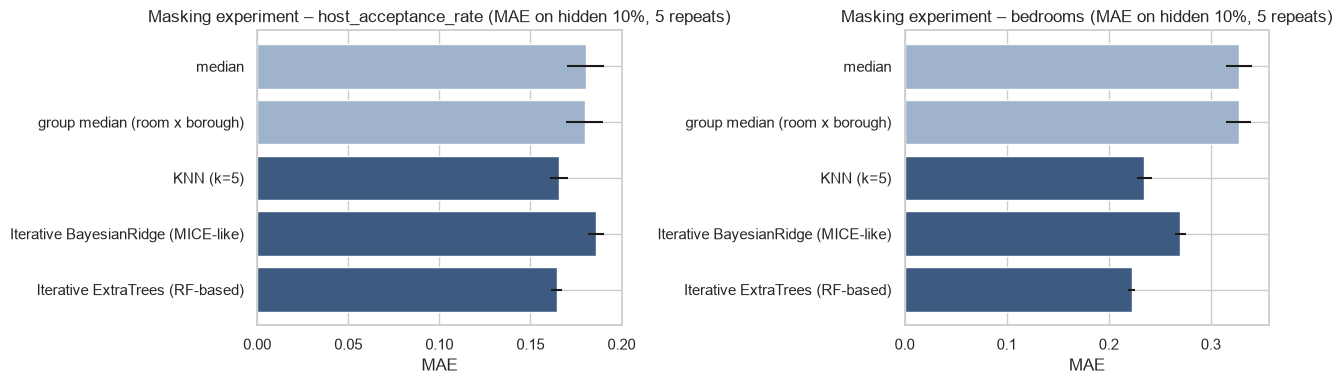

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, c in zip(axes, targets):
    d = mask_res[mask_res.variable == c].groupby("method")["MAE"].agg(["mean", "std"]).reindex(methods)
    ax.barh(range(len(d)), d["mean"], xerr=d["std"], color=["#9FB4CC"] * 2 + ["#3D5A80"] * 3)
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d.index); ax.invert_yaxis()
    ax.set(title=f"Masking experiment – {c} (MAE on hidden 10%, 5 repeats)", xlabel="MAE")
plt.tight_layout(); save(fig, "05_imputation_masking"); plt.show()

In [27]:
# --- Influence of the placeholder-like prices (D15: kept) ---
ph = reg_tr[TARGET] >= 9990
print(f"listings >= $9,990 in train: {ph.sum()} ({ph.mean():.3%}) | their share of total squared deviation from the median log price: "
      f"{((reg_tr.loc[ph, 'log_price'] - reg_tr['log_price'].median()) ** 2).sum() / ((reg_tr['log_price'] - reg_tr['log_price'].median()) ** 2).sum():.2%}")

# --- src tests (18 incl. preprocessing) ---
from importlib import reload
import tests.test_src as tsrc; reload(tsrc)
print(tsrc.run_all().to_string(index=False))

listings >= $9,990 in train: 11 (0.037%) | their share of total squared deviation from the median log price: 1.56%
                                                    test result error
                                    test_find_tf_columns   PASS      
                              test_to_bool_keeps_missing   PASS      
                              test_parse_amenities_valid   PASS      
                          test_parse_amenities_bad_input   PASS      
                                     test_missing_report   PASS      
                        test_checker_finds_duplicate_ids   PASS      
                      test_checker_range_ignores_missing   PASS      
                      test_checker_unknown_column_raises   PASS      
                      test_checker_rejects_non_dataframe   PASS      
                           test_assert_clean_strict_mode   PASS      
                           test_load_missing_file_raises   PASS      
                   test_train_test_uses_saved

## S7 – Evaluation
**What we did**
1. **Split (D13, Tier 3):** host-grouped, room-type-stratified 80/20 holdout shared by both tasks. Train has 29,609 listings and test 7,403, with 0 hosts in common. The split is saved and reproducible, and the test set stays locked until S14.
2. **Audit (D14):** training-only checks of the target tail, domain validity, IQR/LOF, missingness, cardinality, the dummy trap and scaling needs.
3. **Population (D15, Tier 3, student approved):** all price > 0 listings are kept, including the 11 placeholder-like prices ≥ $9,990. These are 0.04% of the rows and account for 1.6% of the total squared deviation in log price. Their influence will be checked with fold-wise target winsorization in S9.
4. **Pipeline (D16, REVIEW #10):** the stateless `build_features()` plus the fold-fitted `make_preprocessor(family, spec)` in `src/preprocess.py` (18/18 src tests pass).

**Findings**
- Matrix sizes for price: `ols` 74 columns (the design matrix with intercept has full rank, 75/75, so the dummy trap is avoided; nested categoricals are left out), `scaled`/`tree` 201 columns (102 neighbourhood levels with `min_frequency=30`, 44 amenity indicators). No NaN after preprocessing.
- Superhost primary set: 22 inputs, without the target and the host-activity block. The ablation has 27 inputs.
- Clip bounds learned on train (1st/99th pct): accommodates 1–10, minimum nights 1–90, maximum nights 7–1125, host NYC listings 1–164.
- **Masking experiment (hide 10% of observed values, 5 repeats):**
  - `bedrooms`: model-based imputers beat median imputation clearly. MAE is 0.222 for iterative ExtraTrees and 0.235 for KNN, against 0.327 for the median, about 30% lower.
  - `host_acceptance_rate`: the gain is small. MAE is 0.164 for ExtraTrees and 0.166 for KNN against 0.180 for the median; BayesianRidge has the lowest RMSE (0.257 vs 0.300).
  - Group medians (room × borough) are no better than the overall median.
  - IterativeImputer showed convergence warnings with the small `max_iter` (results were stable across repeats).
  - This only measures accuracy for values missing at random.

**Decisions and limits**
- The default pipeline uses median imputation plus missingness flags, which is simple and robust. In S8/S9 CV we compare it with KNN and iterative imputation for the `scaled` family, and `bedrooms` median vs 0 (studio hypothesis).
- IQR/LOF flags were not used to delete rows. The int32 `maximum_nights` sentinel and invalid `accommodates = 0` are handled by rules.
- `host_ny_listings` includes the current listing and is assumed to be known when a host prices a listing. Group separation prevents cross-host leakage, but availability at prediction time is a modelling assumption and is stated as one.

**Next step – S8 (ML setup, Tier 3):** CV scheme on the training set (StratifiedGroupKFold by `host_id`, the same folds for every model in a task), metrics as in D5/D6, a DummyRegressor baseline, a random vs grouped CV comparison to show the host-leakage effect, and leakage checks.